## EazyDiner Restaurant Analysis

### Objective

The objective of this project is to collect restaurant data from EazyDiner across seven major Indian cities using Python web scraping techniques and transform the extracted data into a structured dataset for analysis. The project aims to clean and organize the data, perform exploratory data analysis (EDA), create visualizations, and generate business insights related to restaurant distribution, cuisine popularity, dining costs, and location-wise pricing patterns to support data-driven business decisions.

In [2]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
import re
import time


In [3]:
cities = {
    "Delhi NCR": "delhi-ncr",
    "Mumbai": "mumbai",
    "Bengaluru": "bengaluru",
    "Hyderabad": "hyderabad",
    "Chennai": "chennai",
    "Kolkata": "kolkata",
    "Pune": "pune"
}

In [4]:
headers = {
    "User-Agent": "Mozilla/5.0"
}


In [38]:
for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True)
    href = link["href"]

    if text:
        print(text, "->", href)

Open App -> https://1m6m.app.link/ThfKFlxT5Cb
Contact Us -> https://www.eazydiner.com/contact-us
Blogs -> https://www.eazydiner.com/food-trends
Be Prime! -> https://www.eazydiner.com/premium-prime-dining
Home / -> https://www.eazydiner.com/
Pune / -> https://www.eazydiner.com/pune
| View All(4) Outlets -> /pune/restaurants/dadus-sweet-emporio-pune
| View All(26) Outlets -> /pune/restaurants/kiosk-kaffee-pune
| View All(3) Outlets -> /pune/restaurants/maratha-samrat-pune
| View All(15) Outlets -> /pune/restaurants/pvr-pune
| View All(4) Outlets -> /pune/restaurants/mainland-china--pune
« Previous -> https://www.eazydiner.com/pune/restaurants?total=20&page=4
1 -> https://www.eazydiner.com/pune/restaurants?total=20
2 -> https://www.eazydiner.com/pune/restaurants?total=20&page=2
3 -> https://www.eazydiner.com/pune/restaurants?total=20&page=3
4 -> https://www.eazydiner.com/pune/restaurants?total=20&page=4
6 -> https://www.eazydiner.com/pune/restaurants?total=20&page=6
7 -> https://www.eazyd

In [30]:
results = []
MAX_PAGES = 5

for city, slug in cities.items():

    print(f"\nScraping {city}...")
    seen = set()

    for page_no in range(1, MAX_PAGES + 1):

        url = (
            f"https://www.eazydiner.com/{slug}/restaurants"
            f"?total=20&page={page_no}"
        )

        try:
            response = requests.get(
                url,
                headers=headers,
                timeout=20
            )

            print(f"Page {page_no}: Status {response.status_code}")

            if response.status_code != 200:
                break

            soup = BeautifulSoup(response.text, "html.parser")

            cards = soup.select(
                "div.listing-module__chvBCG__res_name"
            )

            page_count = 0

            for name_container in cards:

                h3 = name_container.find("h3")

                if not h3:
                    continue

                name = h3.get_text(" ", strip=True)

                card = name_container.find_parent(
                    "div", class_="max-w-80"
                )

                if not card:
                    continue

                # Restaurant location
                location_element = card.select_one(
                    "div.flex.align-v-center.gap_5.padding.relative"
                )

                location = (
                    location_element.get_text(" ", strip=True)
                    if location_element else ""
                )

                # Cuisine
                cuisine_element = card.select_one("div[title]")

                cuisine = (
                    cuisine_element.get("title", "").strip()
                    if cuisine_element else ""
                )

                # Cost for two
                cost_for_two = None

                for element in card.select("div"):
                    text_value = element.get_text(" ", strip=True)

                    match = re.search(
                        r"₹\s*([\d,]+)\s*for two",
                        text_value,
                        re.IGNORECASE
                    )

                    if match:
                        cost_for_two = int(
                            match.group(1).replace(",", "")
                        )
                        break

                # Avoid duplicate restaurants within this city
                key = (name, location)

                if key in seen:
                    continue

                seen.add(key)
                page_count += 1

                results.append({
                    "Restaurant_Name": name,
                    "City": city,
                    "Cuisine": cuisine,
                    "Restaurant_Location": location,
                    "Cost_For_Two": cost_for_two
                })

            print(f"New restaurants collected: {page_count}")
            print(f"Total for {city}: {len(seen)}")

            time.sleep(1)

        except requests.RequestException as error:
            print(f"Error for {city}, page {page_no}: {error}")
            break



Scraping Delhi NCR...
Page 1: Status 200
New restaurants collected: 8
Total for Delhi NCR: 8
Page 2: Status 200
New restaurants collected: 8
Total for Delhi NCR: 16
Page 3: Status 200
New restaurants collected: 8
Total for Delhi NCR: 24
Page 4: Status 200
New restaurants collected: 8
Total for Delhi NCR: 32
Page 5: Status 200
New restaurants collected: 8
Total for Delhi NCR: 40

Scraping Mumbai...
Page 1: Status 200
New restaurants collected: 8
Total for Mumbai: 8
Page 2: Status 200
New restaurants collected: 8
Total for Mumbai: 16
Page 3: Status 200
New restaurants collected: 8
Total for Mumbai: 24
Page 4: Status 200
New restaurants collected: 8
Total for Mumbai: 32
Page 5: Status 200
New restaurants collected: 8
Total for Mumbai: 40

Scraping Bengaluru...
Page 1: Status 200
New restaurants collected: 8
Total for Bengaluru: 8
Page 2: Status 200
New restaurants collected: 8
Total for Bengaluru: 16
Page 3: Status 200
New restaurants collected: 8
Total for Bengaluru: 24
Page 4: Status 2

In [31]:
df = pd.DataFrame(results, columns=[
    "Restaurant_Name",
    "City",
    "Cuisine",
    "Restaurant_Location",
    "Cost_For_Two"
])


In [32]:
df = df.drop_duplicates().reset_index(drop=True)

In [33]:

df["Cost_For_Two"] = pd.to_numeric(
    df["Cost_For_Two"], errors="coerce"
)

In [34]:
print("\nTotal restaurants:", len(df))


Total restaurants: 280


In [35]:
print("\nRestaurants collected per city:")
print(df.groupby("City").size())


Restaurants collected per city:
City
Bengaluru    40
Chennai      40
Delhi NCR    40
Hyderabad    40
Kolkata      40
Mumbai       40
Pune         40
dtype: int64


In [36]:
print("\nMissing cost values:", df["Cost_For_Two"].isna().sum())

display(df)


Missing cost values: 0


,Restaurant_Name,City,Cuisine,Restaurant_Location,Cost_For_Two
0,Castle's Barbeque,Delhi NCR,"Chinese, Desserts, Mughlai, North Indian, Barb...","Connaught Place (CP), Central Delhi | View All...",2000
1,Hard Rock Cafe,Delhi NCR,"Wraps, Burgers, Continental, Desserts, Fast Fo...","Connaught Place (CP), Central Delhi | View All...",1500
2,Lazeez Affaire - Outer Circle,Delhi NCR,"Kebabs, North Indian, Chinese, Desserts, Birya...","Connaught Place (CP), Central Delhi | View All...",1600
3,Zing,Delhi NCR,"Continental, Asian, Sushi, North Indian, Chine...","The Metropolitan Hotel & Spa, New Delhi",3500
4,"Chutney, Bar + Tandoor",Delhi NCR,"Mughlai, Continental, North Indian","The Metropolitan Hotel & Spa, New Delhi",3000
...,...,...,...,...,...
275,Kiosk kaffee,Pune,"Sandwiches, Shakes, Coffee","SGS Mall, Camp Area | View All(26) Outlets",300
276,Maratha Samrat,Pune,"Seafood, Biryani, Desserts, Maharashtrian","Camp Area, Pune | View All(3) Outlets",1200
277,INOX,Pune,Fast Food,"Bund Garden Road, Pune | View All(15) Outlets",500
278,Indimex,Pune,"North Indian, Pasta, Continental, Iranian","Magarpatta, Pune",1500


### Save the scraped dataset

In [37]:
df.to_csv("eazydiner_multiple_cities.csv", index=False)

print("\nCSV file saved successfully.")



CSV file saved successfully.


### Check the dataset

In [39]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])
print("----------------------------------------------------------------------")
df.info()

Rows: 280
Columns: 5
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Restaurant_Name      280 non-null    object
 1   City                 280 non-null    object
 2   Cuisine              280 non-null    object
 3   Restaurant_Location  280 non-null    object
 4   Cost_For_Two         280 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 11.1+ KB


####  Check missing values

In [40]:
df.isnull().sum()

Restaurant_Name        0
City                   0
Cuisine                0
Restaurant_Location    0
Cost_For_Two           0
dtype: int64

#### Data Types


In [41]:
df.dtypes

Restaurant_Name        object
City                   object
Cuisine                object
Restaurant_Location    object
Cost_For_Two            int64
dtype: object

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Restaurant_Name      280 non-null    object
 1   City                 280 non-null    object
 2   Cuisine              280 non-null    object
 3   Restaurant_Location  280 non-null    object
 4   Cost_For_Two         280 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 11.1+ KB


### EDA

In [43]:
df.describe()

,Cost_For_Two
count,280.000000
mean,1583.321429
std,836.582935
min,200.000000
25%,1000.000000
50%,1500.000000
75%,2000.000000
max,5000.000000


In [45]:
# city Distribution
df["City"].value_counts()

City
Delhi NCR    40
Mumbai       40
Bengaluru    40
Hyderabad    40
Chennai      40
Kolkata      40
Pune         40
Name: count, dtype: int64

In [47]:
# Restaurant Location Distribution
df["Restaurant_Location"].value_counts()

Restaurant_Location
Banjara Hills, Hyderabad                                               15
Sector 1, Salt Lake                                                    13
Connaught Place (CP), Central Delhi                                     9
Shivajinagar, Central Bengaluru                                         8
Jubilee Hills, Hyderabad                                                6
                                                                       ..
JP Nagar, South Bengaluru                                               1
Prestige Trade Tower, Palace Road, Bengaluru | View All(13) Outlets     1
Holiday inn Bengaluru Racecourse                                        1
Vasanth Nagar, Central Bengaluru                                        1
Dhole Patil Road, Pune | View All(4) Outlets                            1
Name: count, Length: 171, dtype: int64

In [49]:
# Average Cost by City
df.groupby("City")["Cost_For_Two"].mean().sort_values(ascending=False)

City
Delhi NCR    2215.00
Bengaluru    1913.75
Mumbai       1873.75
Chennai      1413.25
Pune         1352.50
Hyderabad    1291.25
Kolkata      1023.75
Name: Cost_For_Two, dtype: float64

#### Data Visualizations

In [53]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

#### Cuisine-wise Restaurant Count

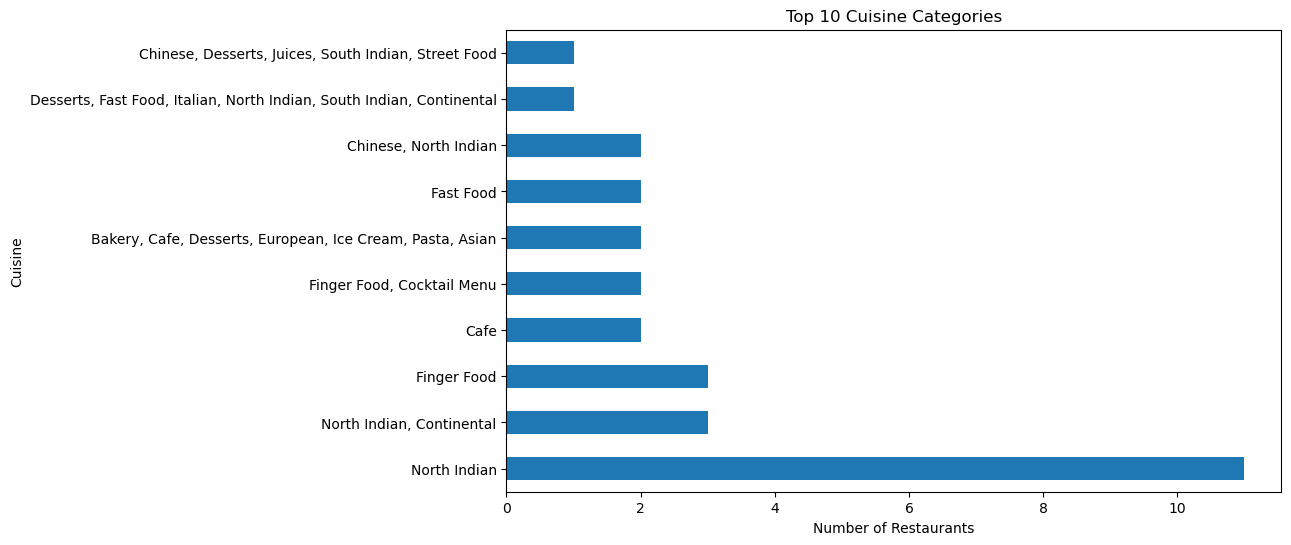

In [56]:
plt.figure(figsize=(10, 6))

df["Cuisine"].value_counts().head(10).plot(kind="barh")

plt.title("Top 10 Cuisine Categories")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")

plt.show()

#### Distribution of Restaurant cost for two people

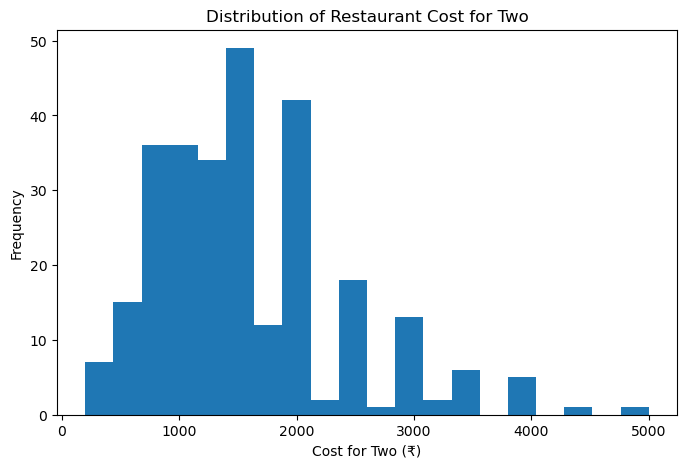

In [58]:
plt.figure(figsize=(8, 5))

plt.hist(df["Cost_For_Two"].dropna(), bins=20)

plt.title("Distribution of Restaurant Cost for Two")
plt.xlabel("Cost for Two (₹)")
plt.ylabel("Frequency")

plt.show()

#### Cuisine Distribution

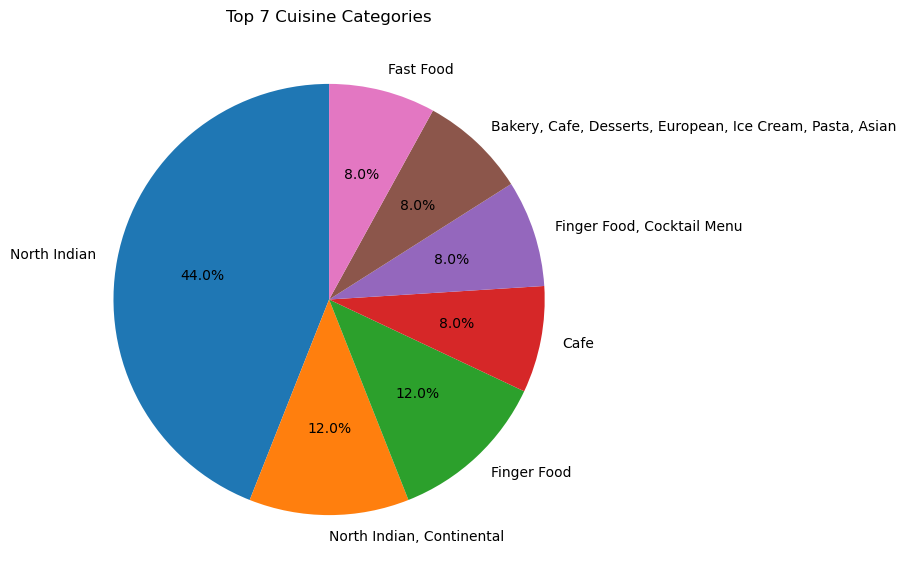

In [61]:
cuisine_counts = df["Cuisine"].value_counts().head(7)

plt.figure(figsize=(7, 7))

plt.pie(
    cuisine_counts,
    labels=cuisine_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 7 Cuisine Categories")

plt.show()

#### City-wise Comparison of Restaurant Costs for Two

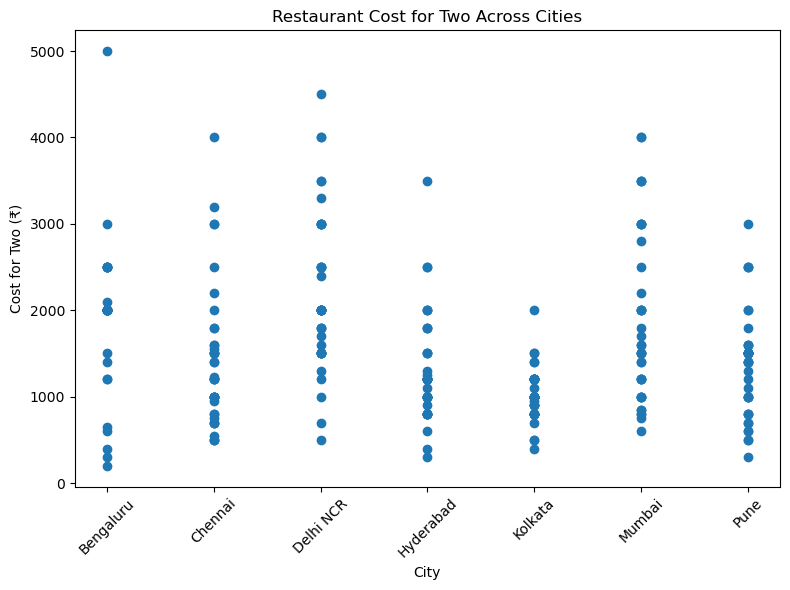

In [65]:
plt.figure(figsize=(8, 6))

city_codes = df["City"].astype("category").cat.codes

plt.scatter(city_codes,df["Cost_For_Two"])

plt.title("Restaurant Cost for Two Across Cities")
plt.xlabel("City")
plt.ylabel("Cost for Two (₹)")

plt.xticks(
    range(len(df["City"].astype("category").cat.categories)),
    df["City"].astype("category").cat.categories,
    rotation=45
)

plt.tight_layout()
plt.show()

#### Most Expensive Restaurants by Cost for Two

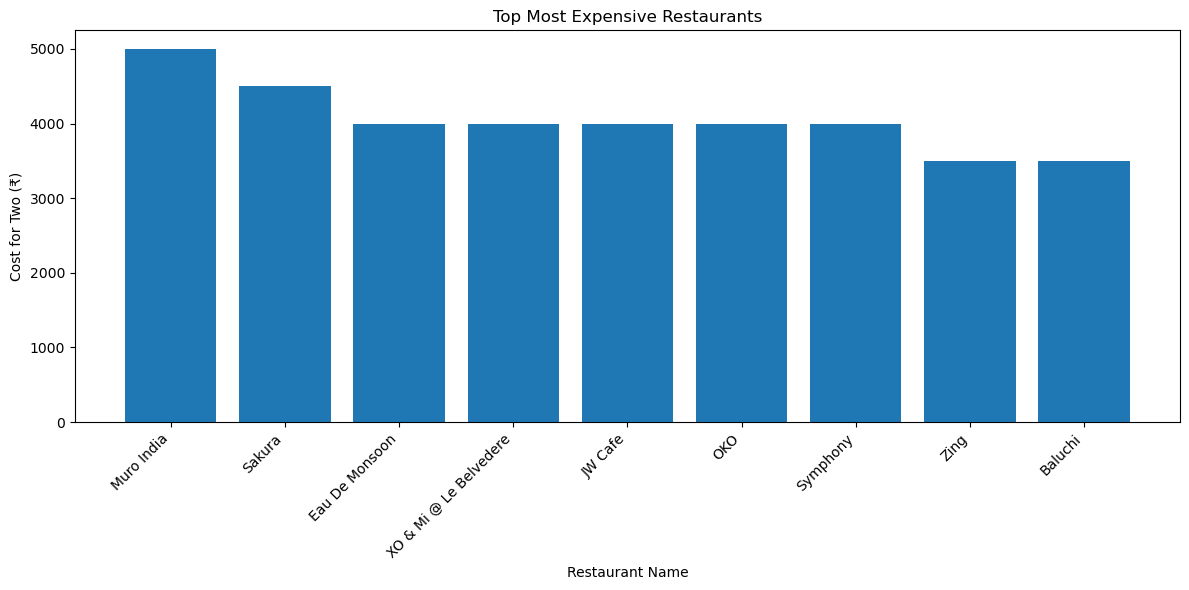

In [67]:
top10 = df.nlargest(10, "Cost_For_Two")

plt.figure(figsize=(12, 6))

plt.bar(top10["Restaurant_Name"], top10["Cost_For_Two"])

plt.title("Top Most Expensive Restaurants")
plt.xlabel("Restaurant Name")
plt.ylabel("Cost for Two (₹)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Restaurant Cost for Two Distribution

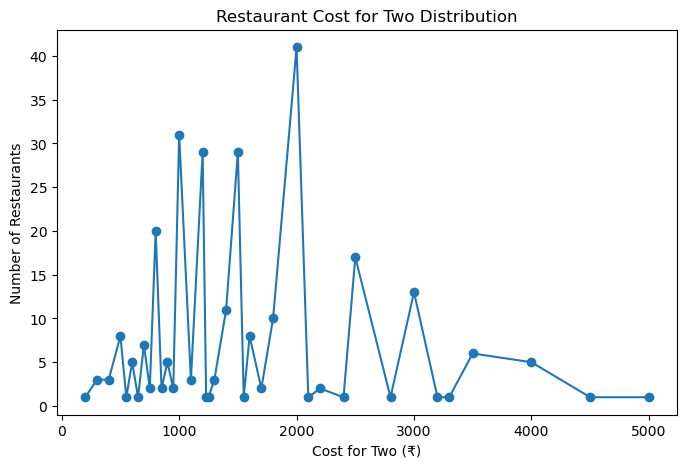

In [69]:
cost = df["Cost_For_Two"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

cost.plot(kind="line", marker="o")

plt.title("Restaurant Cost for Two Distribution")
plt.xlabel("Cost for Two (₹)")
plt.ylabel("Number of Restaurants")

plt.show()

#### OutLiers Analysis

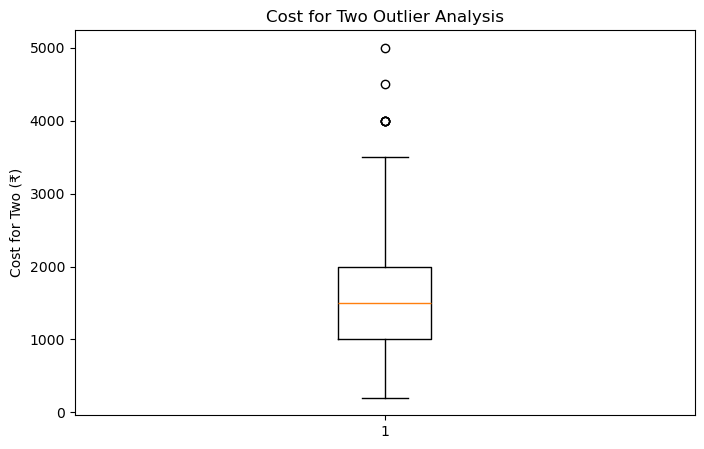

In [71]:
# Cost for Two Outliers

plt.figure(figsize=(8, 5))

plt.boxplot(df["Cost_For_Two"].dropna())

plt.title("Cost for Two Outlier Analysis")
plt.ylabel("Cost for Two (₹)")

plt.show()

#### Restaurant Cost Category Feature Engineering.

In [75]:
df["Cost_Category"] = pd.cut(
    df["Cost_For_Two"],
    bins=[0, 1000, 2000, 3000, float("inf")],
    labels=["Budget", "Mid Range", "Premium", "Luxury"]
)

df.head()

,Restaurant_Name,City,Cuisine,Restaurant_Location,Cost_For_Two,Cost_Category
0,Castle's Barbeque,Delhi NCR,"Chinese, Desserts, Mughlai, North Indian, Barb...","Connaught Place (CP), Central Delhi | View All...",2000,Mid Range
1,Hard Rock Cafe,Delhi NCR,"Wraps, Burgers, Continental, Desserts, Fast Fo...","Connaught Place (CP), Central Delhi | View All...",1500,Mid Range
2,Lazeez Affaire - Outer Circle,Delhi NCR,"Kebabs, North Indian, Chinese, Desserts, Birya...","Connaught Place (CP), Central Delhi | View All...",1600,Mid Range
3,Zing,Delhi NCR,"Continental, Asian, Sushi, North Indian, Chine...","The Metropolitan Hotel & Spa, New Delhi",3500,Luxury
4,"Chutney, Bar + Tandoor",Delhi NCR,"Mughlai, Continental, North Indian","The Metropolitan Hotel & Spa, New Delhi",3000,Premium


#### Business Insights



This EazyDiner Restaurant Analysis project provides valuable insights into restaurant distribution, cuisine preferences, and pricing patterns across seven major Indian cities. The analysis helps understand the restaurant market and supports data-driven business decisions.

- **City-wise Restaurant Distribution:** Identifies cities with the highest and lowest numbers of restaurants in the collected dataset, helping understand restaurant coverage across different locations.

- **Cuisine Popularity Analysis:** Highlights the most frequently listed cuisines, helping identify popular food categories and potential opportunities for restaurant owners.

- **Restaurant Cost Analysis:** Examines the cost for two across restaurants to understand dining price patterns and affordability.

- **Top 10 Most Expensive Restaurants:** Identifies the most expensive restaurants based on cost for two, highlighting premium dining options in the dataset.

- **City-wise Pricing Comparison:** Compares average restaurant costs across cities to identify differences in dining prices.

- **Restaurant Location Analysis:** Examines restaurant distribution across listed locations to identify areas with higher restaurant concentration and possible market opportunities.

- **Cost Category Segmentation:** Classifies restaurants into Budget, Mid Range, Premium, and Luxury categories, making it easier to compare dining options based on price.

- **Pricing Outlier Analysis:** Uses boxplots to identify unusually high or low restaurant costs, which may represent premium dining establishments or values requiring further validation.

#### Business Value

These insights can help restaurant owners understand the competitive landscape, evaluate pricing strategies, identify popular cuisines, and explore potential locations for business expansion. Customers can also use the analysis to compare restaurants based on city, cuisine, and budget.

The project demonstrates practical skills in:

- Python Programming
- Web Scraping using Requests and BeautifulSoup
- Data Cleaning and Preprocessing
- Feature Engineering
- Exploratory Data Analysis (EDA)
- Data Visualization using Matplotlib and Seaborn
- Business Insight Generation

*Note: The findings represent the restaurants collected from EazyDiner and may not reflect the entire restaurant market in each city.*

 ####  Business Recommendations

Based on the EazyDiner Restaurant Analysis, the following recommendations can help restaurant owners and businesses make informed decisions:

- **Focus on Popular Cuisines:** Restaurant owners can consider popular cuisine categories identified in the dataset to attract more customers while differentiating their offerings from competitors.

- **Optimize Pricing Strategies:** Restaurants can compare their cost for two with similar restaurants to establish competitive pricing based on their target customers and market positioning.

- **Explore Market Opportunities:** Cities and locations with fewer restaurants in the collected dataset can be investigated for potential business expansion, subject to customer demand and competition.

- **Target Different Customer Segments:** Restaurants can position themselves in Budget, Mid Range, Premium, or Luxury categories to serve customers with different spending preferences.

- **Strengthen Premium Dining Strategies:** Premium restaurants can focus on service quality, unique dining experiences, and menu differentiation to justify higher prices.

- **Improve Location-Based Planning:** Restaurant businesses can use city-wise and location-wise distribution patterns to evaluate potential locations before investing in new outlets.

- **Validate Pricing Outliers:** Restaurants with unusually high or low costs should be reviewed to identify premium offerings, pricing differences, or possible data inconsistencies.



#### Conclusion

This project demonstrates the complete data analytics workflow, starting from web scraping and ending with business insights and recommendations. Restaurant data was collected from EazyDiner across seven major Indian cities using Python and transformed into a structured dataset for analysis.

The project involved data extraction, data cleaning, feature engineering, exploratory data analysis, and visualization to identify trends in restaurant distribution, cuisine popularity, pricing patterns, and location-wise variations. Different visualizations, including bar charts, histograms, pie charts, scatter plots, and boxplots, helped present the data in an understandable format.

The analysis provides useful insights into restaurant pricing and distribution, supporting better decision-making for restaurant owners, businesses, and customers.

This project demonstrates practical skills in:

- Python Programming
- Web Scraping using Requests and BeautifulSoup
- Data Cleaning and Preprocessing
- Feature Engineering
- Exploratory Data Analysis (EDA)
- Data Visualization using Matplotlib and Seaborn
- Business Recommendations and Insight Generation

Overall, this project demonstrates how web scraping and data analytics can transform raw restaurant information into meaningful insights that support data-driven business decisions.